In [1]:
import pandas as pd
import numpy as np
import requests

In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'

In [3]:
# Downloading our data
response = requests.get(data)
response.raise_for_status()

with open("data.csv", "wb") as f:
    f.write(response.content)

In [4]:
df = pd.read_csv("data.csv")

df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


# Preaparing dataset

In [5]:
df.shape

(10000, 11)

In [6]:
# Selecting columns we are using
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='str')

In [7]:
new_df = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]

new_df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


# EDA

In [8]:
new_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   engine_displacement  10000 non-null  int64  
 1   horsepower           9123 non-null   float64
 2   vehicle_weight       10000 non-null  int64  
 3   model_year           10000 non-null  int64  
 4   fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(2), int64(3)
memory usage: 390.8 KB


In [9]:
# Checking unique rows
for col in new_df.columns:
    print(col)
    print(new_df[col].unique())

engine_displacement
[2180 2390 2320 2130 2580 2290 2270 2370 2330 2410 2240 2440 1900 2170
 2280 2540 2490 2300 2350 2610 2160 2260 2010 2460 2080 2070 2620 2560
 2420 2200 2530 2360 2340 2150 2500 2400 2740 2140 2190 1980 1960 2100
 1890 2310 1910 2110 2450 2650 2220 2020 2550 2430 2470 2250 2090 2380
 2230 1820 2510 2210 1920 2120 2040 1930 1880 2480 1780 1670 1950 1940
 2640 2060 2000 2570 2710 2680 1790 2600 1970 2700 1810 2030 2630 2520
 1870 2670 2050 1990 2690 2590 1850 1750 1860 1840 2790 1700 2720 2660
 1800 2960 2750 1760 2830 2820 2760 2780 2730 1710 1720 1830 2910 2940
 1770 1740 2840 1590 1690 3020 2900 2770 3110 1730 2850 1680 2800 3000
 2870]
horsepower
[243. 272. 267. 258. 304. 266. 250. 279. 251. 280.  nan 277. 202. 226.
 234. 299. 264. 260. 291. 246. 302. 249. 254. 265. 216. 294. 240. 255.
 273. 270. 262. 296. 239. 248. 282. 238. 231. 289. 232. 321. 235. 257.
 284. 233. 198. 221. 290. 219. 263. 256. 210. 252. 261. 268. 283. 237.
 298. 278. 229. 241. 244. 245. 228. 269

In [10]:
# Checking fuel_efficiency_mpg distribution
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

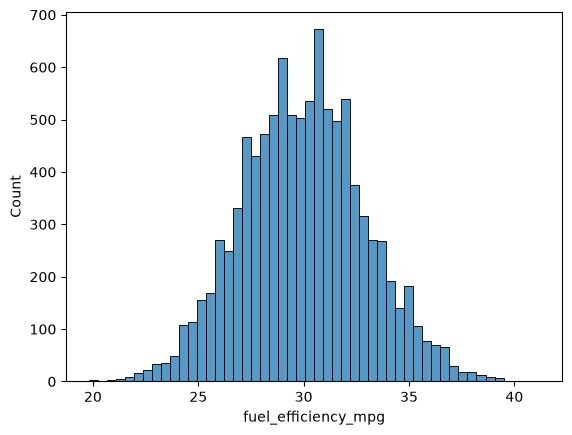

In [11]:
sns.histplot(df['fuel_efficiency_mpg'], bins=50)

### The distribution of our curve forms a bell curve. This is good for our model

# 1. There's one column with missing values. What is it?

In [12]:
new_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   engine_displacement  10000 non-null  int64  
 1   horsepower           9123 non-null   float64
 2   vehicle_weight       10000 non-null  int64  
 3   model_year           10000 non-null  int64  
 4   fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(2), int64(3)
memory usage: 390.8 KB


### The column 'horsepower' has missing values

# 2. What's the median (50% percentile) for variable 'horsepower'?

In [13]:
new_df.describe()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
count,10000.000000,9123.000000,10000.000000,10000.000000,10000.000000
mean,2268.807000,254.446016,4286.754000,1999.549500,29.997700
std,183.447355,22.844613,266.212491,14.207925,2.930245
min,1590.000000,171.000000,3320.000000,1975.000000,19.800000
25%,2150.000000,239.000000,4110.000000,1987.000000,28.000000
50%,2270.000000,254.000000,4280.000000,2000.000000,30.000000
75%,2390.000000,270.000000,4470.000000,2012.000000,31.900000
max,3110.000000,334.000000,5460.000000,2024.000000,41.200000


### The median (50% percentile) is 254

# 3. Which option gives better RMSE?

In [14]:
# Splitting the data
n = len(new_df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = new_df.iloc[idx[:n_train]]
df_val = new_df.iloc[idx[n_train:n_train + n_val]]
df_test = new_df.iloc[idx[n_train + n_val:]]

## Identify the column with missing values

In [15]:
df_train['horsepower'].isna().sum()

np.int64(538)

In [16]:
df_val.horsepower.isna().sum()

np.int64(176)

## Calculate the mean of horsepower

In [17]:
mean = df_train.horsepower.mean()

In [18]:
mean

np.float64(254.46338337605272)

## Fill horsepower with 0

In [19]:
df_train_zero = df_train.copy()
df_val_zero = df_val.copy()

In [20]:
# Replace the missing horsepower values with 0
df_train_zero.horsepower = df_train_zero.horsepower.fillna(0)
df_val_zero.horsepower = df_val_zero.horsepower.fillna(0)

In [21]:
df_train_zero.horsepower.isnull().sum()

np.int64(0)

In [22]:
df_val_zero.horsepower.isnull().sum()

np.int64(0)

## Prepare X and y

In [23]:
# Separate the target variable from the features.
X_train = df_train_zero.drop('fuel_efficiency_mpg', axis=1)
y_train = df_train_zero.fuel_efficiency_mpg

X_val = df_val_zero.drop('fuel_efficiency_mpg', axis=1)
y_val = df_val_zero.fuel_efficiency_mpg

In [24]:
# Train the linear regression without regularization.
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-0. ,-0. ,-0. , 0.1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['engine_displacement','horsepower','vehicle_weight','model_year']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-153.9
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [25]:
# To make predictions
y_pred = model.predict(X_val)

In [26]:
# Calculate RMSE
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(y_val, y_pred) ** 0.5

round(rmse, 3)

2.205

## Fill NaN with the mean

In [27]:
mean = df_train.horsepower.mean()
mean

np.float64(254.46338337605272)

In [28]:
df_train_mean = df_train.copy()
df_val_mean = df_val.copy()

# fill the missing horsepower values with that mean
df_train_mean.horsepower = df_train_mean.horsepower.fillna(mean)
df_val_mean.horsepower = df_val_mean.horsepower.fillna(mean)

In [29]:
df_train_mean.horsepower.isnull().sum()

np.int64(0)

In [30]:
df_val_mean.horsepower.isnull().sum()

np.int64(0)

In [31]:
# Create X and y
X_train = df_train_mean.drop('fuel_efficiency_mpg', axis=1)
y_train = df_train_mean.fuel_efficiency_mpg

X_val = df_val_mean.drop('fuel_efficiency_mpg', axis=1)
y_val = df_val_mean.fuel_efficiency_mpg

In [32]:
# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-0. ,-0.01,-0. , 0.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['engine_displacement','horsepower','vehicle_weight','model_year']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-153.3
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [33]:
# Predictions
y_pred = model.predict(X_val)

In [34]:
# Calculate RMSE
rmse = mean_squared_error(y_val, y_pred) ** 0.5

round(rmse, 3)

2.202

### Fill missing horsepower with 0 - RMSE = 2.205
### Fill missing horsepower with mean - RMSE = 2.202
### Since lower RMSE is better, the mean option performs slightly better.

# 4. Which r gives the best RMSE?

In [35]:
df_train_zero = df_train.copy()
df_val_zero = df_val.copy()

df_train_zero.horsepower = df_train_zero.horsepower.fillna(0)
df_val_zero.horsepower = df_val_zero.horsepower.fillna(0)

In [36]:
# Create x and y
x_train = df_train_zero.drop('fuel_efficiency_mpg', axis=1)
y_train = df_train_zero.fuel_efficiency_mpg

x_val = df_val_zero.drop('fuel_efficiency_mpg', axis=1)
y_val = df_val_zero.fuel_efficiency_mpg

In [37]:
from sklearn.linear_model import Ridge

In [38]:
r = [0, 0.01, 0.1, 1, 5, 10, 100]

In [39]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    model = Ridge(alpha=r)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    rmse = mean_squared_error(y_val, y_pred) ** 0.5

    print(r, round(rmse, 4))

0 2.2018
0.01 2.2018
0.1 2.2018
1 2.2018
5 2.2018
10 2.2018
100 2.2018


## r = 0, because all options have the same RMSE at 4 decimal places, we choose the smallest value

# 5. What's the value of std?

In [40]:
scores = []

for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:

    # Splitting the data
    n = len(new_df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = new_df.iloc[idx[:n_train]]
    df_val = new_df.iloc[idx[n_train:n_train + n_val]]
    df_test = new_df.iloc[idx[n_train + n_val:]]

    # Fill missing values with 0
    df_train.horsepower = df_train.horsepower.fillna(0)
    df_val.horsepower = df_val.horsepower.fillna(0)

    # Prepare X and y
    X_train = df_train.drop('fuel_efficiency_mpg', axis=1)
    y_train = df_train.fuel_efficiency_mpg

    X_val = df_val.drop('fuel_efficiency_mpg', axis=1)
    y_val = df_val.fuel_efficiency_mpg

    # Train model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_val)

    # RMSE
    rmse = mean_squared_error(y_val, y_pred) ** 0.5
    scores.append(rmse)

print(scores)
print(round(np.std(scores), 3))

[2.2392041430507534, 2.2021128210837344, 2.1634197787530796, 2.2043588768529316, 2.2018800943317713, 2.245785150908142, 2.269721207951653, 2.1907945999354204, 2.216611201694419, 2.2070365928234095]
0.029


### 0.029

# 6. What's the RMSE on the test dataset?

In [41]:
# Split the data using seed 9
np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = new_df.iloc[idx[:n_train]]
df_val = new_df.iloc[idx[n_train:n_train + n_val]]
df_test = new_df.iloc[idx[n_train + n_val:]]

# Combine train and validation
df_full_train = pd.concat([df_train, df_val])

# Fill missing values with 0
df_full_train.horsepower = df_full_train.horsepower.fillna(0)
df_test.horsepower = df_test.horsepower.fillna(0)

# Prepare X and y
X_full_train = df_full_train.drop('fuel_efficiency_mpg', axis=1)
y_full_train = df_full_train.fuel_efficiency_mpg

X_test = df_test.drop('fuel_efficiency_mpg', axis=1)
y_test = df_test.fuel_efficiency_mpg

# Train model
model = Ridge(alpha=0.001)
model.fit(X_full_train, y_full_train)

# Predict
y_pred = model.predict(X_test)

# RMSE
rmse = mean_squared_error(y_test, y_pred) ** 0.5
round(rmse, 3)

2.236

### 2.236